In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    roc_curve,
    recall_score,
    classification_report
)

import xgboost as xgb

print("All libraries imported successfully!")
print("XGBoost Version:", xgb.__version__)

All libraries imported successfully!
XGBoost Version: 3.4.1


In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)

print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)

Training Data Shape: (5634, 20)
Testing Data Shape: (1409, 20)


In [4]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.drop("customerID", axis=1)

print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 20)


In [6]:
X_train = train_df.drop("Churn", axis=1)

y_train = train_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Training Features Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("\nChurn Distribution:")
print(y_train.value_counts())

Training Features Shape: (5634, 19)
Training Target Shape: (5634,)

Churn Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [7]:
def create_features(data):
    data = data.copy()

    # 1. Tenure groups
    data["tenure_group"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["0-12", "13-24", "25-48", "49-72"]
    )

    # 2. Average monthly spending
    data["avg_monthly_spend"] = (
        data["TotalCharges"] /
        data["tenure"].replace(0, np.nan)
    )

    # 3. Number of subscribed services
    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    data["service_count"] = (
        data[service_columns].eq("Yes").sum(axis=1)
    )

    # 4. Long-term contract indicator
    data["long_term_contract"] = (
        data["Contract"].isin(["One year", "Two year"]).astype(int)
    )

    return data


X_train = create_features(X_train)

print("Feature Engineering Completed!")
print("Training Features Shape:", X_train.shape)

X_train.head()

Feature Engineering Completed!
Training Features Shape: (5634, 23)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,avg_monthly_spend,service_count,long_term_contract
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,...,Yes,Month-to-month,No,Electronic check,49.20,1701.65,25-48,48.618571,3,0
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,No,Month-to-month,No,Mailed check,75.10,1151.55,13-24,76.770000,2,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,...,No,Two year,No,Mailed check,40.55,590.35,13-24,45.411538,3,1
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,...,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,25-48,73.296154,5,1
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,...,No,Month-to-month,No,Electronic check,44.55,44.55,0-12,44.550000,1,0


In [8]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Features:", len(numerical_features) + len(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend', 'service_count', 'long_term_contract']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']

Total Features: 23


In [9]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [10]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative Class:", negative_count)
print("Positive Class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

# Create XGBoost pipeline
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss"
    ))
])

print("\nXGBoost Pipeline Created Successfully!")

Negative Class: 4139
Positive Class: 1495
Scale Pos Weight: 2.768561872909699

XGBoost Pipeline Created Successfully!


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}

print("5-Fold Cross-Validation Ready!")

5-Fold Cross-Validation Ready!


In [12]:
xgb_scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("XGBoost Results")
print("Mean ROC-AUC:", xgb_scores["test_roc_auc"].mean())
print("Mean F1 Score:", xgb_scores["test_f1"].mean())

XGBoost Results
Mean ROC-AUC: 0.8450348317319719
Mean F1 Score: 0.6381142860820102


In [13]:
print("XGBoost ROC-AUC:", xgb_scores["test_roc_auc"].mean())
print("XGBoost F1:", xgb_scores["test_f1"].mean())

XGBoost ROC-AUC: 0.8450348317319719
XGBoost F1: 0.6381142860820102


In [14]:
print("XGBoost F1:", xgb_scores["test_f1"].mean())

XGBoost F1: 0.6381142860820102


In [15]:
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_params = {
    "classifier__C": np.logspace(-3, 2, 10),
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["liblinear", "lbfgs"]
}

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_params,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

lr_search.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(lr_search.best_params_)

print("Best Logistic Regression ROC-AUC:")
print(lr_search.best_score_)

Best Logistic Regression Parameters:
{'classifier__solver': 'liblinear', 'classifier__class_weight': None, 'classifier__C': np.float64(0.046415888336127795)}
Best Logistic Regression ROC-AUC:
0.8460232418115352


In [16]:
xgb_params = {
    "classifier__n_estimators": [200, 300, 400, 500],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__scale_pos_weight": [
        scale_pos_weight * 0.8,
        scale_pos_weight,
        scale_pos_weight * 1.2
    ]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("Best XGBoost ROC-AUC:")
print(xgb_search.best_score_)

Best XGBoost Parameters:
{'classifier__subsample': 0.7, 'classifier__scale_pos_weight': np.float64(3.3222742474916385), 'classifier__n_estimators': 500, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.8}
Best XGBoost ROC-AUC:
0.8487684854801977


In [17]:
best_lr_model = lr_search.best_estimator_

lr_tuned_scores = cross_validate(
    best_lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Tuned Logistic Regression")
print("ROC-AUC:", lr_tuned_scores["test_roc_auc"].mean())
print("F1 Score:", lr_tuned_scores["test_f1"].mean())

Tuned Logistic Regression
ROC-AUC: 0.8460232418115352
F1 Score: 0.5912792133383373


In [18]:
best_xgb_model = xgb_search.best_estimator_

xgb_tuned_scores = cross_validate(
    best_xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Tuned XGBoost")
print("ROC-AUC:", xgb_tuned_scores["test_roc_auc"].mean())
print("F1 Score:", xgb_tuned_scores["test_f1"].mean())

Tuned XGBoost
ROC-AUC: 0.8487684854801977
F1 Score: 0.625289885983942


In [19]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression (Tuned)",
        "Random Forest (Baseline)",
        "XGBoost (Tuned)"
    ],
    "ROC-AUC": [
        lr_tuned_scores["test_roc_auc"].mean(),
        0.826,
        xgb_tuned_scores["test_roc_auc"].mean()
    ],
    "F1 Score": [
        lr_tuned_scores["test_f1"].mean(),
        0.561,
        xgb_tuned_scores["test_f1"].mean()
    ]
})

print(comparison_df)

comparison_df.to_csv(
    "../outputs/task1_part2_model_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

                         Model   ROC-AUC  F1 Score
0  Logistic Regression (Tuned)  0.846023  0.591279
1     Random Forest (Baseline)  0.826000  0.561000
2              XGBoost (Tuned)  0.848768  0.625290
Comparison table saved successfully!


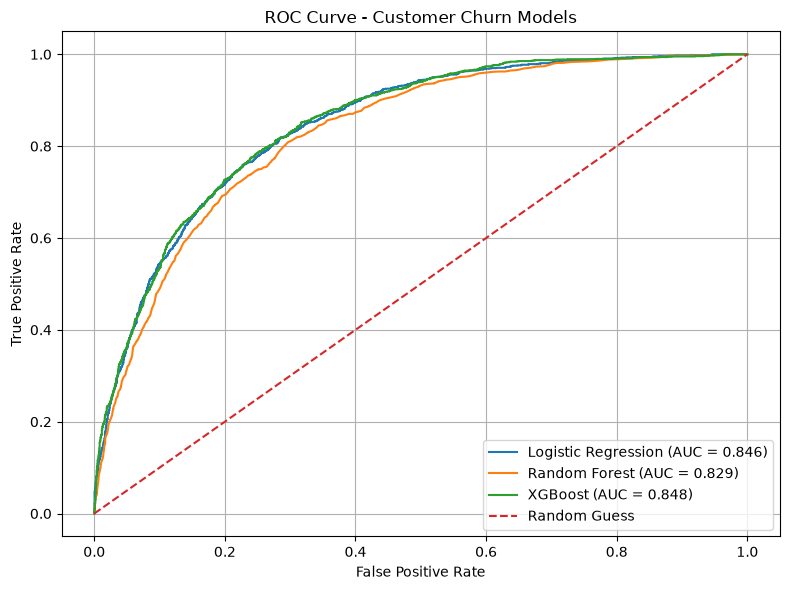

ROC Curve saved successfully!


In [22]:
from sklearn.model_selection import cross_val_predict

lr_probs = cross_val_predict(
    best_lr_model, X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

rf_probs = cross_val_predict(
    rf_pipeline, X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

xgb_probs = cross_val_predict(
    best_xgb_model, X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

plt.figure(figsize=(8, 6))

for name, probs in [
    ("Logistic Regression", lr_probs),
    ("Random Forest", rf_probs),
    ("XGBoost", xgb_probs)
]:
    fpr, tpr, thresholds = roc_curve(y_train, probs)
    auc_score = roc_auc_score(y_train, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Models")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("../outputs/task1_part2_roc_curve.png")
plt.show()

print("ROC Curve saved successfully!")

In [21]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [23]:
thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:
    predictions = (xgb_probs >= threshold).astype(int)

    recall = recall_score(y_train, predictions)
    f1 = f1_score(y_train, predictions)

    threshold_results.append({
        "Threshold": threshold,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

valid_thresholds = threshold_df[
    threshold_df["Recall"] >= 0.75
]

best_threshold_row = valid_thresholds.iloc[-1]

best_threshold = best_threshold_row["Threshold"]

print("Selected Threshold:", best_threshold)
print("Recall:", best_threshold_row["Recall"])
print("F1 Score:", best_threshold_row["F1 Score"])

Selected Threshold: 0.5900000000000002
Recall: 0.7505016722408027
F1 Score: 0.6338983050847458


Top 5 Important Features:
                             Feature  Importance
39      cat__Contract_Month-to-month    0.285912
6            num__long_term_contract    0.235497
19  cat__InternetService_Fiber optic    0.047661
21            cat__OnlineSecurity_No    0.032198
30               cat__TechSupport_No    0.024295


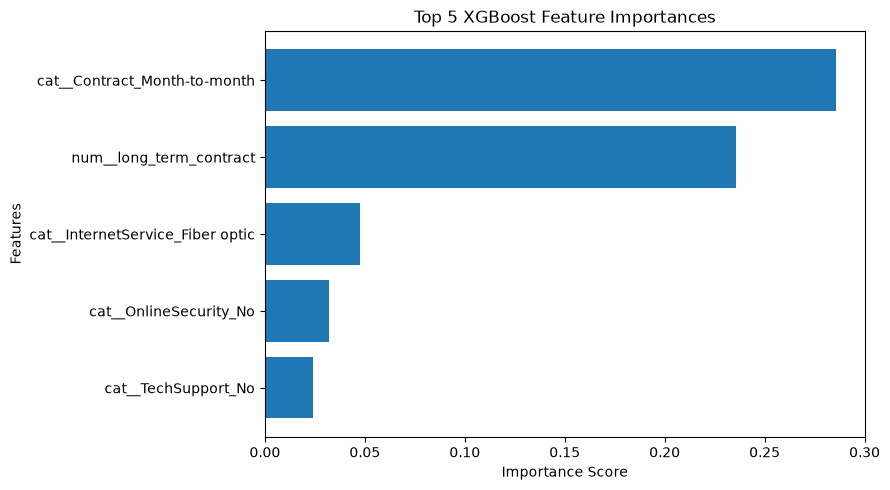

Feature importance chart saved successfully!


In [24]:
# Train the best XGBoost model on training data
best_xgb_model.fit(X_train, y_train)

# Get feature names
feature_names = (
    best_xgb_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance scores
importances = (
    best_xgb_model
    .named_steps["classifier"]
    .feature_importances_
)

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select top 5 features
top_5_features = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(5)

print("Top 5 Important Features:")
print(top_5_features)

# Plot feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    top_5_features["Feature"],
    top_5_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 5 XGBoost Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("../outputs/task1_part2_feature_importance.png")
plt.show()

print("Feature importance chart saved successfully!")

Business Interpretation of Top 5 Features

1. Month-to-month Contract: Customers with month-to-month contracts have greater flexibility to leave. The business can improve retention by offering attractive long-term contract options.

2. Long-term Contract: Long-term contracts are an important retention-related feature. Businesses can encourage customers to choose annual or two-year plans.

3. Fiber Optic Internet: Fiber optic internet service is associated with customer churn patterns. The business should investigate customer satisfaction, service quality, and pricing.

4. No Online Security: Customers without online security may benefit from additional security services and suitable promotional offers.

5. No Tech Support: Customers without technical support may need more assistance. Offering accessible technical support could help improve customer satisfaction.

Conclusion: Contract type is the most influential feature in the XGBoost model. The business should prioritize month-to-month customers and improve customer support and service offerings to reduce churn.

Final Conclusion – Task 1 (Part 2)

- Built an XGBoost classification pipeline to predict customer churn.
- Handled class imbalance using "scale_pos_weight".
- Tuned Logistic Regression and XGBoost using RandomizedSearchCV.
- Compared Logistic Regression, Random Forest, and XGBoost.
- XGBoost achieved the best ROC-AUC of 0.8488 and F1 score of 0.6253.
- Selected a classification threshold of 0.59 to achieve approximately 75% recall.
- Identified the top five features influencing model predictions.
- Saved the model comparison table, ROC curve, and feature importance chart.

Business Recommendation: Focus on month-to-month contract customers, improve customer support, and offer suitable retention plans to reduce customer churn.

Note: Feature importance indicates predictive contribution, not proof that a feature causes churn.